# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

Notebook ini menganalisis data transaksi **Olist** (marketplace e-commerce Brazil) untuk menjawab dua pertanyaan bisnis seputar **keterlambatan pengiriman** dan **kualitas produk berdasarkan review pelanggan**.

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan Anda harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

### Pertanyaan Bisnis

- **Pertanyaan 1 (Operasional / Logistik):** Berapa persentase pesanan berstatus *delivered* yang terlambat yaitu tanggal diterima pelanggan melewati *order_estimated_delivery_date* di setiap state Brazil selama Januari–Agustus 2018, dan state mana yang persentasenya tertinggi?
- **Pertanyaan 2 (Produk / Kepuasan Pelanggan):** Kategori produk mana yang memiliki rata-rata *review_score* terendah dengan volume penjualan minimal 100 item selama 2018, dan bagaimana kaitan rata-rata waktu pengiriman kategori tersebut dengan skor review-nya?

**Pemenuhan elemen SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| **Specific** | Keterlambatan pesanan delivered per state, bukan kualitas layanan secara umum | Kategori produk dengan review terendah pada volume tertentu |
| **Measurable** | Persentase order terlambat dan peringkat state | Rata-rata review_score, jumlah item, rata-rata hari kirim |
| **Action-Oriented** | State terburuk menjadi prioritas evaluasi mitra logistik | Kategori terburuk menjadi prioritas perbaikan kualitas dan ekspektasi kirim |
| **Relevant** | Keterlambatan menurunkan kepuasan dan memicu review buruk | Review buruk menekan repeat order dan reputasi marketplace |
| **Time-bound** | Januari–Agustus 2018 | Januari–Agustus 2018 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)

## Data Wrangling

### Gathering Data

#### Load df orders, order_items, products, customers, reviews, payments, dan geolocation

Dataset Olist terdiri dari 9 tabel yang saling berelasi. Tabel orders menjadi pusat karena memuat tanggal pembelian, tanggal diterima, dan estimasi pengiriman. tiga kolom kunci untuk pertanyaan pertama.

In [2]:
DATA_DIR = "data"

orders_df = pd.read_csv(
    f"{DATA_DIR}/orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
)
order_items_df = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
products_df = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
category_df = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
customers_df = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
reviews_df = pd.read_csv(
    f"{DATA_DIR}/order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)
payments_df = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
geo_df = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")

tables = {
    "orders": orders_df,
    "order_items": order_items_df,
    "products": products_df,
    "category_translation": category_df,
    "customers": customers_df,
    "reviews": reviews_df,
    "payments": payments_df,
    "geolocation": geo_df,
}
for name, df in tables.items():
    print(f"{name:<20} {df.shape[0]:>9,} baris x {df.shape[1]:>2} kolom")

print(
    "Rentang tanggal pembelian:",
    orders_df.order_purchase_timestamp.min().date(),
    "s/d",
    orders_df.order_purchase_timestamp.max().date(),
)
print("Jumlah state pelanggan:", customers_df.customer_state.nunique())

orders                  99,441 baris x  8 kolom
order_items            112,650 baris x  7 kolom
products                32,951 baris x  9 kolom
category_translation        71 baris x  2 kolom
customers               99,441 baris x  5 kolom
reviews                 99,224 baris x  7 kolom
payments               103,886 baris x  5 kolom
geolocation          1,000,163 baris x  5 kolom
Rentang tanggal pembelian: 2016-09-04 s/d 2018-10-17
Jumlah state pelanggan: 27


**Insight:**
- Delapan tabel berhasil dimuat dengan total lebih dari 1,5 juta baris; tabel orders (99.441 baris) menjadi penghubung utama seluruh analisis.
- Rentang pembelian adalah 4 September 2016 – 17 Oktober 2018, namun volume pada 2016 (329 pesanan) dan setelah Agustus 2018 (20 pesanan) sangat tipis sehingga periode analisis dibatasi Januari 2017 – Agustus 2018.
- Pesanan tersebar di 27 state; SP, RJ, dan MG menguasai lebih dari 60% pesanan sehingga rata-rata nasional sangat dipengaruhi ketiga state tersebut.
- Tabel geolocation memuat 1.000.163 baris koordinat yang perlu diagregasi per prefix kode pos sebelum dapat dipakai.

### Assessing Data

#### Identifying missing value, duplicate, invalid value, dan inconsistent value

In [3]:
# --- 1. Missing value ---
missing_orders = (
    orders_df.isna().sum()
    .to_frame("missing")
    .assign(persen=lambda d: (d["missing"] / len(orders_df) * 100).round(2))
    .query("missing > 0")
)
print("Missing value pada orders_df:")
print(missing_orders.to_string())

print("Missing value terbesar pada products_df:")
print(products_df.isna().sum().sort_values(ascending=False).head(3).to_string())

print("Missing review_comment_message:", reviews_df.review_comment_message.isna().sum())

# --- 2. Duplicate ---
print("Duplikat order_id (orders)     :", orders_df.order_id.duplicated().sum())
print("Duplikat review_id (reviews)   :", reviews_df.review_id.duplicated().sum())
print("Duplikat order_id (reviews)    :", reviews_df.order_id.duplicated().sum())
print("Duplikat baris (geolocation)   :", geo_df.duplicated().sum())

# --- 3. Invalid value ---
print("review_score di luar 1-5       :", (~reviews_df.review_score.between(1, 5)).sum())
print("price <= 0 (order_items)       :", (order_items_df.price <= 0).sum())
print("payment_value <= 0 (payments)  :", (payments_df.payment_value <= 0).sum())
print("product_category_name kosong   :", products_df.product_category_name.isna().sum())

# --- 4. Inconsistent value ---
delivered = orders_df.dropna(subset=["order_delivered_customer_date"])
terlalu_cepat = (
    delivered.order_delivered_customer_date < delivered.order_purchase_timestamp
).sum()
print("Tanggal terima < tanggal beli  :", terlalu_cepat)

# --- 5. Outlier durasi pengiriman ---
durasi = (
    delivered.order_delivered_customer_date - delivered.order_purchase_timestamp
).dt.days
print("Statistik durasi pengiriman (hari):")
print(durasi.describe().round(2).to_string())
print("Durasi > 60 hari:", (durasi > 60).sum(), "| Durasi negatif:", (durasi < 0).sum())

Missing value pada orders_df:
                               missing  persen
order_approved_at                  160    0.16
order_delivered_carrier_date      1783    1.79
order_delivered_customer_date     2965    2.98
Missing value terbesar pada products_df:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
Missing review_comment_message: 58247
Duplikat order_id (orders)     : 0
Duplikat review_id (reviews)   : 814
Duplikat order_id (reviews)    : 551
Duplikat baris (geolocation)   : 261831
review_score di luar 1-5       : 0
price <= 0 (order_items)       : 0
payment_value <= 0 (payments)  : 9
product_category_name kosong   : 610
Tanggal terima < tanggal beli  : 0
Statistik durasi pengiriman (hari):
count    96476.00
mean        12.09
std          9.55
min          0.00
25%          6.00
50%         10.00
75%         15.00
max        209.00
Durasi > 60 hari: 288 | Durasi negatif: 0


**Steps to Take:**
1. **Missing value**: buang 2.965 pesanan tanpa tanggal diterima karena pesanan belum selesai dan tidak dapat dipakai menghitung keterlambatan; isi 610 kategori produk yang kosong dengan "unknown".
2. **Duplicate**: hapus duplikasi review (814 review_id dan 551 order_id ganda) dengan hanya menyimpan review terakhir per order; duplikasi baris geolocation tidak dihapus tetapi diagregasi menjadi satu sentroid per prefix kode pos.
3. **Invalid value**: buang 9 baris pembayaran dengan payment_value <= 0 agar nilai transaksi tidak bias.
4. **Inconsistent value**: tidak ditemukan tanggal terima yang mendahului tanggal beli; aturan penyaringan tetap diterapkan sebagai pengaman.
5. **Outlier**: 288 pesanan dengan durasi kirim di atas 60 hari (maksimum 209 hari) tidak dibuang karena merepresentasikan pengiriman nyata yang justru relevan dengan analisis keterlambatan; hanya dilaporkan.

**Insight:**
- Kolom order_delivered_customer_date kosong pada 2.965 pesanan (2,98%), sejalan dengan jumlah pesanan berstatus shipped, canceled, dan unavailable, sehingga missing ini bersifat struktural, bukan acak.
- Terdapat 551 order yang memiliki lebih dari satu review dan 814 review_id duplikat; bila dibiarkan, satu pesanan dapat terhitung dua kali saat menghitung rata-rata skor.
- Nilai tidak valid relatif sedikit (9 pembayaran bernilai nol, 610 kategori produk kosong), sehingga pembersihan tidak banyak mengurangi data.
- Distribusi durasi pengiriman condong ke kanan: median 10 hari tetapi rata-rata 12,09 hari dan nilai maksimum 209 hari, menandakan ada ekor panjang pengiriman sangat lambat.

### Cleaning Data

#### Fixing missing value, duplicate, invalid value, dan inconsistent value

In [4]:
# 1. Buang order tanpa tanggal terima dan tanggal yang tidak konsisten,
#    lalu batasi ke periode analisis Januari 2017 - Agustus 2018
clean_orders = orders_df.dropna(subset=["order_delivered_customer_date"]).copy()
clean_orders = clean_orders[
    clean_orders.order_delivered_customer_date >= clean_orders.order_purchase_timestamp
]
clean_orders = clean_orders[
    (clean_orders.order_purchase_timestamp >= "2017-01-01")
    & (clean_orders.order_purchase_timestamp < "2018-09-01")
]
print(
    f"Order setelah filter: {len(clean_orders):,} "
    f"({len(clean_orders) / len(orders_df):.1%} dari data awal)"
)

# 2. Deduplikasi review: ambil review terakhir per order
reviews_clean = (
    reviews_df.sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]]
)
print(f"Review setelah deduplikasi: {len(reviews_clean):,}")

# 3. Produk: isi kategori kosong dan terjemahkan ke bahasa Inggris
products_clean = products_df.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna(
    "unknown"
)
products_clean = products_clean.merge(category_df, on="product_category_name", how="left")
products_clean["product_category_name_english"] = products_clean[
    "product_category_name_english"
].fillna("unknown")

# 4. Item pesanan: buang harga tidak valid
items_clean = order_items_df[order_items_df.price > 0].copy()

# 5. Agregasi item ke level order (harga, ongkir, jumlah item, kategori dominan)
items_agg = (
    items_clean.merge(
        products_clean[["product_id", "product_category_name_english"]],
        on="product_id",
        how="left",
    )
    .groupby("order_id")
    .agg(
        n_items=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        product_category=(
            "product_category_name_english",
            lambda s: s.mode().iat[0] if not s.mode().empty else "unknown",
        ),
    )
    .reset_index()
)

# 6. Pembayaran: total nilai dan tipe pembayaran dominan per order
payments_agg = (
    payments_df.groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_type=("payment_type", lambda s: s.mode().iat[0]),
    )
    .reset_index()
)

# 7. Sentroid koordinat per prefix kode pos (untuk analisis geospatial)
geo_centroid = (
    geo_df.groupby("geolocation_zip_code_prefix")
    .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"))
    .reset_index()
)
customers_geo = customers_df.merge(
    geo_centroid,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
)

# 8. Gabungkan menjadi satu tabel level order
all_df = (
    clean_orders.merge(
        customers_geo[
            ["customer_id", "customer_unique_id", "customer_city", "customer_state", "lat", "lng"]
        ],
        on="customer_id",
        how="left",
    )
    .merge(items_agg, on="order_id", how="left")
    .merge(reviews_clean, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
)

# 9. Fitur turunan untuk analisis
all_df["delivery_days"] = (
    all_df.order_delivered_customer_date - all_df.order_purchase_timestamp
).dt.days
all_df["delay_days"] = (
    all_df.order_delivered_customer_date - all_df.order_estimated_delivery_date
).dt.days
all_df["is_late"] = all_df["delay_days"] > 0
all_df["purchase_month"] = all_df.order_purchase_timestamp.dt.to_period("M").astype(str)

print("Bentuk all_df:", all_df.shape)
sisa_missing = all_df.isna().sum()
print("Kolom yang masih memiliki missing value:")
print(sisa_missing[sisa_missing > 0].to_string())
print(f"Persentase order terlambat (seluruh periode): {all_df.is_late.mean():.2%}")

Order setelah filter: 96,204 (96.7% dari data awal)
Review setelah deduplikasi: 98,673
Bentuk all_df: (96204, 24)
Kolom yang masih memiliki missing value:
order_approved_at                14
order_delivered_carrier_date      1
lat                             264
lng                             264
review_score                    643
Persentase order terlambat (seluruh periode): 6.79%


**Insight:**
- Setelah cleaning diperoleh 96.204 pesanan (96,7% dari data awal) dalam rentang Januari 2017 – Agustus 2018, dengan 24 kolom siap analisis.
- Masih tersisa 643 pesanan tanpa review_score (0,67%) dan 264 pesanan tanpa koordinat; keduanya dibiarkan dan otomatis dikecualikan saat metrik terkait dihitung.
- Tingkat keterlambatan seluruh periode adalah 6,79%, artinya sekitar 6–7 dari 100 pesanan tiba melewati estimasi.
- Kolom turunan delivery_days, delay_days, dan is_late memungkinkan seluruh analisis keterlambatan dilakukan tanpa menghitung ulang selisih tanggal.

## Exploratory Data Analysis (EDA)

### Explore keterlambatan pengiriman per state dan performa kategori produk

EDA dibagi menjadi dua bagian sesuai pertanyaan bisnis: (1) distribusi keterlambatan per state dan tren bulanannya, (2) performa kategori produk berdasarkan review dan waktu pengiriman.

In [5]:
# ---------- EDA Pertanyaan 1: keterlambatan per state (2018) ----------
q1_df = all_df[all_df.order_purchase_timestamp.dt.year == 2018].copy()

late_by_state = (
    q1_df.groupby("customer_state")
    .agg(
        total_order=("order_id", "nunique"),
        late_order=("is_late", "sum"),
        avg_delivery_days=("delivery_days", "mean"),
    )
    .assign(
        late_rate=lambda d: (d.late_order / d.total_order * 100).round(2),
        avg_delivery_days=lambda d: d.avg_delivery_days.round(1),
    )
    .sort_values("late_rate", ascending=False)
)

print("10 state dengan tingkat keterlambatan tertinggi (Jan-Agu 2018):")
print(late_by_state.head(10).to_string())
print(f"Rata-rata keterlambatan nasional 2018: {q1_df.is_late.mean():.2%}")
print(f"Jumlah order 2018 yang dianalisis   : {len(q1_df):,}")

monthly_late = (
    all_df.groupby("purchase_month")
    .agg(total_order=("order_id", "nunique"), late_rate=("is_late", "mean"))
    .assign(late_rate=lambda d: (d.late_rate * 100).round(2))
)
print("Tren keterlambatan bulanan:")
print(monthly_late.to_string())

10 state dengan tingkat keterlambatan tertinggi (Jan-Agu 2018):
                total_order  late_order  avg_delivery_days  late_rate
customer_state                                                       
AL                      198          44               23.2      22.22
MA                      346          69               20.9      19.94
CE                      633         121               21.7      19.12
PI                      258          43               18.9      16.67
PA                      453          75               25.0      16.56
SE                      146          24               17.7      16.44
TO                      144          22               17.8      15.28
MS                      411          59               15.8      14.36
BA                     1726         243               18.7      14.08
ES                     1047         144               15.8      13.75
Rata-rata keterlambatan nasional 2018: 7.73%
Jumlah order 2018 yang dianalisis   : 52,778
Tren k

In [6]:
# ---------- EDA Pertanyaan 2: performa kategori produk (2018) ----------
cat_perf = (
    q1_df.groupby("product_category")
    .agg(
        total_item=("n_items", "sum"),
        avg_review=("review_score", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
        avg_price=("total_price", "mean"),
        late_rate=("is_late", "mean"),
    )
    .query("total_item >= 100")
    .assign(
        avg_review=lambda d: d.avg_review.round(2),
        avg_delivery_days=lambda d: d.avg_delivery_days.round(1),
        late_rate=lambda d: (d.late_rate * 100).round(1),
        avg_price=lambda d: d.avg_price.round(0),
    )
    .sort_values("avg_review")
)

print("10 kategori dengan rata-rata review terendah (volume >= 100 item):")
print(cat_perf.head(10).to_string())
print(f"Jumlah kategori yang dianalisis: {len(cat_perf)}")
print(
    "Korelasi durasi kirim vs review (level kategori):",
    round(cat_perf.avg_delivery_days.corr(cat_perf.avg_review), 3),
)
print(
    "Korelasi durasi kirim vs review (level order):",
    round(q1_df[["delivery_days", "review_score"]].corr().iloc[0, 1], 3),
)

10 kategori dengan rata-rata review terendah (volume >= 100 item):
                           total_item  avg_review  avg_delivery_days  avg_price  late_rate
product_category                                                                          
office_furniture                  867        3.66               21.6      223.0        7.7
audio                             200        3.85               13.2      185.0       12.3
fixed_telephony                   100        3.86               12.4      318.0        8.2
construction_tools_safety         140        3.99               10.9      254.0        2.5
bed_bath_table                   5871        4.00               11.7      111.0        8.2
unknown                           652        4.01               12.2      124.0        8.6
furniture_living_room             233        4.02               11.7      162.0        8.0
telephony                        2280        4.02               12.4       82.0        8.7
computers_accessories  

**Insight:**
- Dari 52.778 pesanan pada 2018, tingkat keterlambatan nasional adalah 7,73%, tetapi sebarannya sangat timpang: AL mencapai 22,22% (44 dari 198 pesanan) — hampir tiga kali rata-rata nasional — diikuti MA 19,94%, CE 19,12%, PI 16,67%, dan PA 16,56%.
- Rata-rata durasi pengiriman di state bermasalah jauh lebih panjang (AL 23,2 hari, PA 25,0 hari) dibanding median nasional 10 hari, menunjukkan akar masalahnya adalah jarak dan keterbatasan jaringan logistik.
- Tren bulanan tidak stabil: keterlambatan melonjak pada November 2017 (12,40%), Februari 2018 (14,14%), dan Maret 2018 (18,96%), lalu turun drastis pada Juni 2018 (1,16%) — pola ini mengindikasikan gangguan logistik periodik, bukan sekadar kenaikan volume.
- Dari 47 kategori dengan volume minimal 100 item, office_furniture memiliki rata-rata review terendah (3,66) sekaligus durasi kirim terlama (21,6 hari); kategori bervolume besar seperti bed_bath_table (5.871 item) juga masih berada di batas 4,00.
- Korelasi durasi kirim vs review adalah -0,702 pada level kategori dan -0,367 pada level order: semakin lama pengiriman, semakin rendah skor review.

## Visualization & Explanatory Analysis

### Pertanyaan 1: State mana yang memiliki persentase keterlambatan pengiriman tertinggi pada Januari–Agustus 2018?

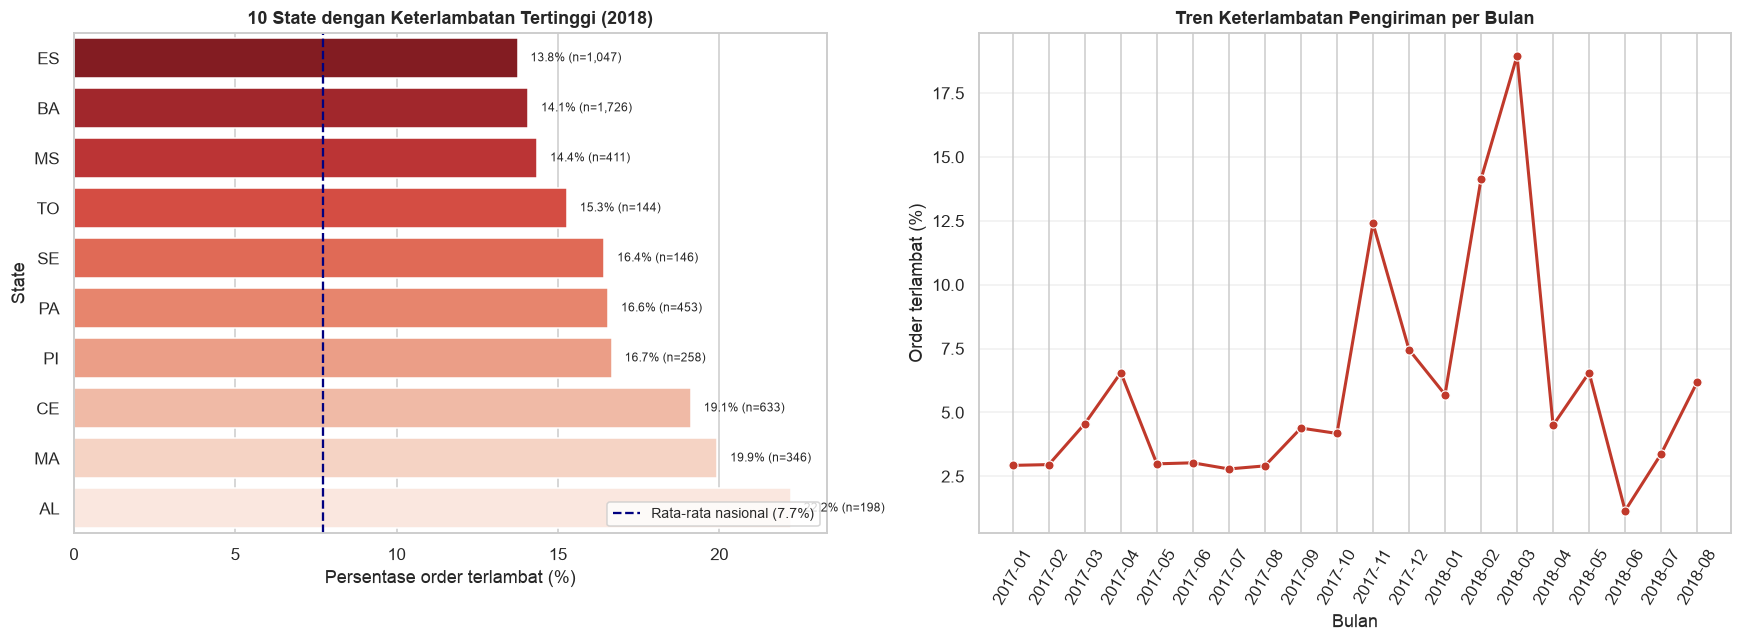

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10 = late_by_state.head(10).sort_values("late_rate")
sns.barplot(
    data=top10,
    y=top10.index,
    x="late_rate",
    hue=top10.index,
    palette="Reds_r",
    legend=False,
    ax=axes[0],
)
axes[0].axvline(
    q1_df.is_late.mean() * 100,
    color="navy",
    linestyle="--",
    linewidth=1.5,
    label=f"Rata-rata nasional ({q1_df.is_late.mean():.1%})",
)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].set_title("10 State dengan Keterlambatan Tertinggi (2018)")
axes[0].set_xlabel("Persentase order terlambat (%)")
axes[0].set_ylabel("State")
for i, (rate, total) in enumerate(zip(top10.late_rate, top10.total_order)):
    axes[0].text(rate + 0.4, i, f"{rate:.1f}% (n={total:,})", va="center", fontsize=8)

monthly_plot = monthly_late.reset_index()
sns.lineplot(
    data=monthly_plot,
    x="purchase_month",
    y="late_rate",
    marker="o",
    linewidth=2,
    color="#c0392b",
    ax=axes[1],
)
axes[1].set_title("Tren Keterlambatan Pengiriman per Bulan")
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Order terlambat (%)")
axes[1].tick_params(axis="x", rotation=60)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Kategori produk mana yang berkinerja terburuk berdasarkan review dan waktu pengiriman pada 2018?

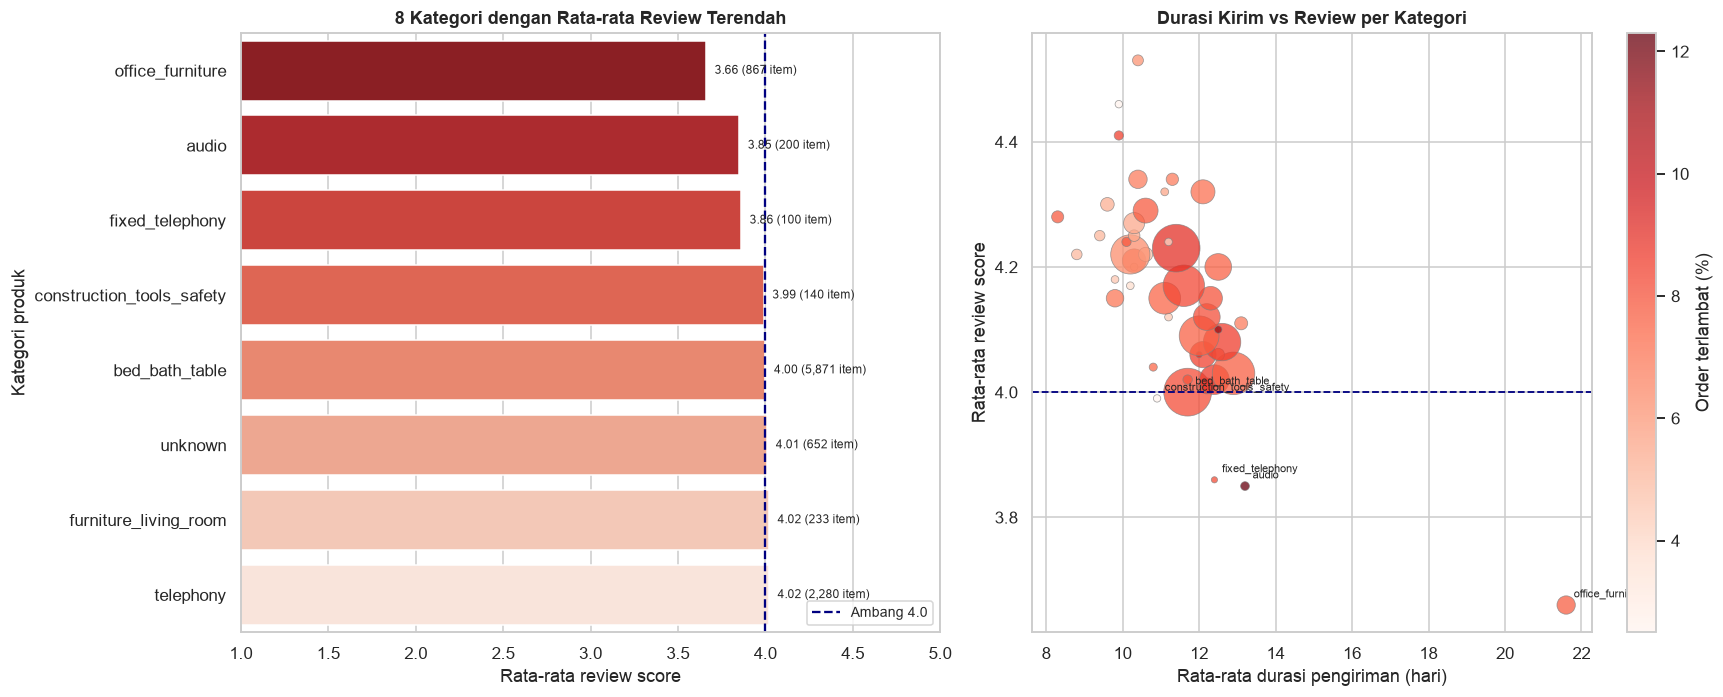

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

bottom8 = cat_perf.head(8).sort_values("avg_review")
sns.barplot(
    data=bottom8,
    y=bottom8.index,
    x="avg_review",
    hue=bottom8.index,
    palette="Reds_r",
    legend=False,
    ax=axes[0],
)
axes[0].axvline(4.0, color="navy", linestyle="--", linewidth=1.5, label="Ambang 4.0")
axes[0].set_xlim(1, 5)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].set_title("8 Kategori dengan Rata-rata Review Terendah")
axes[0].set_xlabel("Rata-rata review score")
axes[0].set_ylabel("Kategori produk")
for i, (score, item) in enumerate(zip(bottom8.avg_review, bottom8.total_item)):
    axes[0].text(score + 0.05, i, f"{score:.2f} ({item:,} item)", va="center", fontsize=8)

scatter = axes[1].scatter(
    cat_perf.avg_delivery_days,
    cat_perf.avg_review,
    s=cat_perf.total_item / 6,
    c=cat_perf.late_rate,
    cmap="Reds",
    alpha=0.75,
    edgecolor="grey",
    linewidth=0.5,
)
for category in cat_perf.head(5).index:
    axes[1].annotate(
        category,
        (cat_perf.loc[category, "avg_delivery_days"], cat_perf.loc[category, "avg_review"]),
        fontsize=7,
        xytext=(5, 5),
        textcoords="offset points",
    )
axes[1].axhline(4.0, color="navy", linestyle="--", linewidth=1.2)
axes[1].set_title("Durasi Kirim vs Review per Kategori")
axes[1].set_xlabel("Rata-rata durasi pengiriman (hari)")
axes[1].set_ylabel("Rata-rata review score")
plt.colorbar(scatter, ax=axes[1], label="Order terlambat (%)")

plt.tight_layout()
plt.show()

**Insight 1:**
- Grafik batang kiri menempatkan AL, MA, dan CE sebagai tiga state dengan keterlambatan tertinggi (22,2%, 19,9%, 19,1%), semuanya jauh di atas garis putus-putus rata-rata nasional 7,7%.
- Grafik garis kanan memperlihatkan lonjakan tajam pada Februari–Maret 2018 (14,1% dan 19,0%) yang tidak diikuti lonjakan volume pesanan sebesar itu — indikasi gangguan kapasitas atau operasional, bukan semata musim ramai.

**Insight 2:**
- Pada panel kategori, delapan kategori terburuk semuanya berada di bawah ambang 4,0; office_furniture paling rendah (3,66) dengan volume 867 item dan durasi kirim 21,6 hari.
- Scatter plot menegaskan pola negatif: titik-titik dengan durasi kirim panjang dan warna gelap (keterlambatan tinggi) berkumpul di area skor review rendah, sehingga perbaikan pengiriman berpotensi langsung menaikkan kepuasan.

## Analisis Lanjutan (Opsional)

### RFM Analysis (Recency, Frequency, Monetary)

RFM digunakan untuk mengelompokkan pelanggan berdasarkan perilaku pembelian: **Recency** (seberapa baru terakhir belanja), **Frequency** (jumlah pesanan), dan **Monetary** (total belanja). Setiap metrik diberi skor 1–4 menggunakan *quartile binning* (pd.qcut), lalu kombinasi skor dipetakan ke segmen bisnis. Tujuannya agar rekomendasi tidak berhenti di level operasional, tetapi juga menyasar pelanggan yang paling bernilai dan yang berisiko churn.

In [9]:
snapshot_date = all_df.order_purchase_timestamp.max() + pd.Timedelta(days=1)

rfm_df = (
    all_df.groupby("customer_unique_id")
    .agg(
        last_order=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_price", "sum"),
    )
    .reset_index()
)
rfm_df["recency"] = (snapshot_date - rfm_df.last_order).dt.days

# Skor 1-4: 4 = paling baik (recency kecil, frequency & monetary besar)
rfm_df["r_score"] = pd.qcut(rfm_df.recency, 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = pd.qcut(rfm_df.frequency.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df.monetary, 4, labels=[1, 2, 3, 4]).astype(int)


def segment_customer(row):
    r, f, m = row.r_score, row.f_score, row.m_score
    if r >= 3 and f >= 3 and m >= 3:
        return "Champions"
    if r >= 3 and f <= 2:
        return "New / Potential"
    if r == 2 and f >= 3:
        return "At Risk (High Value)"
    if r == 1 and f >= 3:
        return "Hibernating (High Value)"
    if r == 1:
        return "Lost"
    return "Need Attention"


rfm_df["segment"] = rfm_df.apply(segment_customer, axis=1)

segment_summary = (
    rfm_df.groupby("segment")
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_revenue=("monetary", "sum"),
    )
    .assign(
        revenue_share=lambda d: d.total_revenue / d.total_revenue.sum() * 100,
        customer_share=lambda d: d.customers / d.customers.sum() * 100,
    )
    .sort_values("total_revenue", ascending=False)
    .round(2)
)
print("Ringkasan segmen pelanggan (RFM):")
print(segment_summary.to_string())

Ringkasan segmen pelanggan (RFM):
                          customers  avg_recency  avg_frequency  avg_monetary  total_revenue  revenue_share  customer_share
segment                                                                                                                    
New / Potential               23212       111.41           1.00        137.47     3190864.63          24.21           24.93
Champions                     12069       112.23           1.13        240.50     2902570.44          22.02           12.96
Need Attention                22878       194.66           1.01         93.61     2141560.38          16.25           24.57
Hibernating (High Value)      11461       448.57           1.05        144.59     1657176.79          12.57           12.31
At Risk (High Value)          11740       276.43           1.06        141.15     1657047.28          12.57           12.61
Lost                          11737       447.86           1.00        138.93     1630588.42      

### Geospatial Analysis: sebaran keterlambatan berdasarkan lokasi pelanggan

Koordinat pelanggan (lat, lng) yang berasal dari sentroid kode pos dipakai untuk memetakan tingkat keterlambatan per state. Visualisasi ini memperlihatkan pola spasial apakah keterlambatan terkonsentrasi di wilayah tertentu sehingga keputusan alokasi logistik bisa diambil berdasarkan lokasi, bukan hanya peringkat angka.

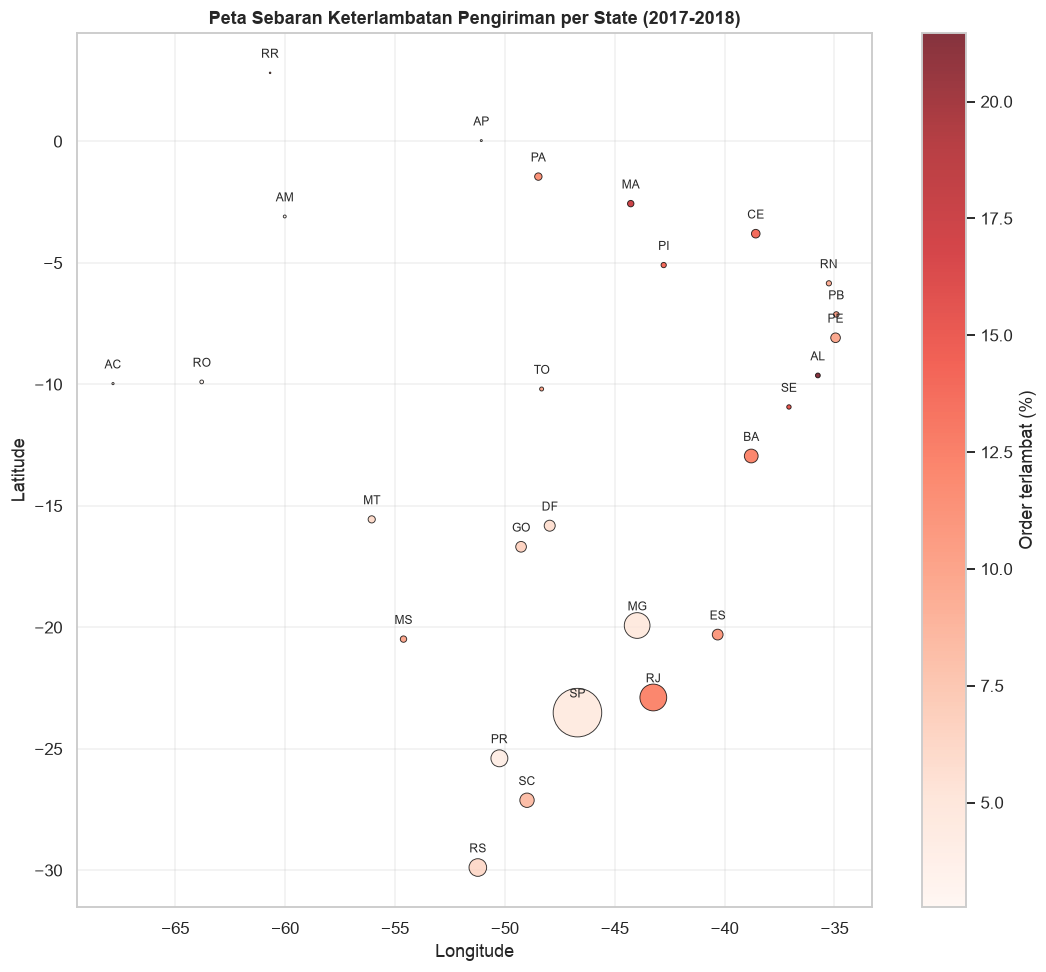

customer_state  late_rate  orders
            AL  21.464646     396
            MA  17.531557     713
            SE  15.361446     332
            PI  13.894737     475
            CE  13.825609    1273


In [10]:
state_geo = (
    all_df.groupby("customer_state")
    .agg(
        late_rate=("is_late", "mean"),
        orders=("order_id", "nunique"),
        lat=("lat", "median"),
        lng=("lng", "median"),
    )
    .reset_index()
)
state_geo["late_rate"] *= 100

fig, ax = plt.subplots(figsize=(10, 9))
scatter = ax.scatter(
    state_geo.lng,
    state_geo.lat,
    s=state_geo.orders / 40,
    c=state_geo.late_rate,
    cmap="Reds",
    alpha=0.8,
    edgecolor="black",
    linewidth=0.6,
)
for _, row in state_geo.iterrows():
    ax.annotate(
        row.customer_state,
        (row.lng, row.lat),
        fontsize=8,
        ha="center",
        va="center",
        xytext=(0, 12),
        textcoords="offset points",
    )
plt.colorbar(scatter, ax=ax, label="Order terlambat (%)")
ax.set_title("Peta Sebaran Keterlambatan Pengiriman per State (2017-2018)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    state_geo.sort_values("late_rate", ascending=False)
    .head(5)[["customer_state", "late_rate", "orders"]]
    .to_string(index=False)
)

**Insight:**
- Sebaran pelanggan didominasi segmen New / Potential (23.212 pelanggan, 24,93%) dan Need Attention (22.878, 24,57%), sementara Champions hanya 12.069 pelanggan (12,96%) tetapi menyumbang 22,02% pendapatan.
- Rata-rata frequency seluruh segmen hanya sekitar 1,0–1,1 pesanan per pelanggan, menandakan repeat order sangat rendah — hampir semua pelanggan berbelanja satu kali.
- Segmen At Risk (High Value) dan Hibernating (High Value) masing-masing menyumbang 12,57% pendapatan dengan recency 276 dan 449 hari, sehingga berisiko hilang tanpa intervensi.
- Peta menunjukkan keterlambatan tinggi terkonsentrasi di state bagian timur laut dan utara (AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%) — wilayah yang jauh dari pusat distribusi di São Paulo.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Januari–Agustus 2018, 7,73% dari 52.778 pesanan delivered tiba melewati estimasi pengiriman. Keterlambatan tidak tersebar merata: AL (22,22%), MA (19,94%), CE (19,12%), PI (16,67%), dan PA (16,56%) berada jauh di atas rata-rata nasional, dengan durasi kirim 19–25 hari dibanding median nasional 10 hari. Tren bulanan juga menunjukkan lonjakan tajam pada Februari–Maret 2018 (14,14% dan 18,96%) yang tidak sebanding dengan kenaikan volume pesanan.
- **Conclusion pertanyaan 2:** Dari 47 kategori dengan volume minimal 100 item, office_furniture memiliki rata-rata review terendah (3,66) dengan durasi kirim terlama (21,6 hari), diikuti audio (3,85) dan fixed_telephony (3,86). Kategori bervolume besar seperti bed_bath_table (5.871 item, skor 4,00), telephony (2.280 item, 4,02), dan computers_accessories (4.648 item, 4,03) berada tepat di ambang 4,0 sehingga dampaknya luas. Korelasi durasi kirim vs review sebesar -0,702 di level kategori dan -0,367 di level order membuktikan bahwa pengiriman lambat adalah pemicu utama review rendah.

**Rekomendasi Action Item:**

1. **Prioritaskan evaluasi mitra logistik di AL, MA, CE, PI, dan PA** — tambah opsi kurir lokal atau buka hub transit regional, karena kelima state ini menanggung 16–22% keterlambatan sementara rata-rata nasional hanya 7,7%.
2. **Sesuaikan estimasi pengiriman agar lebih realistis untuk wilayah luar Jawa** — estimasi yang terlalu optimis membuat pesanan tercatat terlambat meski pengiriman normal, dan langsung menekan skor review.
3. **Siapkan kapasitas logistik tambahan pada Februari–Maret** dan periode kampanye November–Desember, mengikuti pola lonjakan keterlambatan yang berulang (hingga 18,96% pada Maret 2018).
4. **Audit kualitas dan SLA pengemasan pada office_furniture, bed_bath_table, telephony, dan computers_accessories** — mulai dari deskripsi produk, kualitas kemasan, hingga waktu proses seller, karena kategori ini bervolume besar dengan skor di sekitar atau di bawah 4,0.
5. **Jalankan program retensi dua arah**: voucher atau prioritas layanan untuk Champions (12,96% pelanggan, 22,02% pendapatan) dan kampanye win-back untuk At Risk / Hibernating (High Value) yang sudah 276–449 hari tidak bertransaksi.
6. **Dorong pembelian kedua pada segmen New / Potential** (24,93% pelanggan) melalui follow-up pasca-pengiriman, karena rata-rata frequency hanya 1,0 pesanan per pelanggan.
7. **Pantau metrik keterlambatan per state melalui dashboard** setiap bulan agar tim operasional dapat mendeteksi anomali sebelum berdampak pada review.

## Menyimpan Data untuk Dashboard

In [11]:
output_cols = [
    "order_id",
    "customer_unique_id",
    "customer_city",
    "customer_state",
    "lat",
    "lng",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_days",
    "delay_days",
    "is_late",
    "product_category",
    "n_items",
    "total_price",
    "total_freight",
    "review_score",
    "payment_type",
    "payment_value",
]

export_df = all_df[output_cols].sort_values("order_purchase_timestamp").reset_index(drop=True)

os.makedirs("dashboard", exist_ok=True)
export_df.to_csv("dashboard/main_data.csv", index=False)

print("main_data.csv tersimpan:", export_df.shape)
print(f"Ukuran file: {os.path.getsize('dashboard/main_data.csv') / 1e6:.1f} MB")
print(export_df.dtypes.to_string())

main_data.csv tersimpan: (96204, 19)
Ukuran file: 22.2 MB
order_id                                    str
customer_unique_id                          str
customer_city                               str
customer_state                              str
lat                                     float64
lng                                     float64
order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
delivery_days                             int64
delay_days                                int64
is_late                                    bool
product_category                            str
n_items                                   int64
total_price                             float64
total_freight                           float64
review_score                            float64
payment_type                                str
payment_value                           float64
